# PortfolioPilot - Milestone 3: cleaning, EDA, dimension reduction, feature set



**Run the cells in order, top to bottom.** Each cell uses variables made by the cells before it.
After a kernel restart, start again from cell 1.

Rule for M3: the test sets are created in Step 3 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

In [97]:
# Install the packages required by the notebook
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [98]:
%pip install numpy pandas scipy scikit-learn matplotlib yfinance

## Step 1 - Setting up

### Configuring paths and reproducibility

This cell mounts Google Drive, moves into the raw-data folder, defines the input and output locations, and centralizes the random seed and SCF column mapping. Keeping these settings here makes the remaining cells reproducible and easier to adapt to another environment.

In [99]:
from google.colab import drive
drive.mount("/content/drive")          # a pop-up asks you to allow access: click Allow

import os
os.chdir("/content/drive/MyDrive/Portfolio_pilot/data/raw")  # upload data in your drive following the same path
print("Working in:", os.getcwd())
print("Files here:", os.listdir())

from pathlib import Path
SCF_FILE = Path("SCFP2025.csv")
OUT_DIR  = Path("outputs")


SEED = 7275 #to ensure everytime the notebokk runs it will have same results.

# SCF column names in the summary extract (checked against the SCF codebook)
# Predefine by the team based on Domain Knowledge
COLS = {
    "household_id": "YY1", "record_id": "Y1", "weight": "WGT", "age": "AGE",
    "income": "INCOME", "networth": "NETWORTH", "liq": "LIQ", "debt": "DEBT",
    "equity": "EQUITY", "fin": "FIN", "yes_risk": "YESFINRISK", "no_risk": "NOFINRISK",
}
IMPLICATE = 1
SPLIT = {"train": 0.70, "val": 0.15, "test": 0.15}
CAP_QUANTILE = 0.99            # caps for ratio features, from training data

K_RANGE = [2, 3, 4, 5, 6]
CLUSTER_METHOD = "kmeans"      # "kmeans" or "gmm"
CHOSEN_K = None                # None = automatic (best silhouette); or set a number after Step 9
MIN_CLUSTER_SHARE = 0.05
N_BOOTSTRAP = 20               # use 3 for a quick test, 20 for final results
PCA_THRESHOLD = 0.80

TICKERS = ["SPY", "VEA", "VWO", "AGG", "TLT", "TIP", "VNQ", "GLD", "DBC"] # Predefine by the team based on Domain Knowledge
ETF_START, ETF_END = "2016-01-01", "2026-01-01"   # end is exclusive: data through 2025-12-31
ETF_TRAIN_END, ETF_VAL_END = "2021-12-31", "2023-12-31"
ETF_FILE = OUT_DIR / "raw" / "etf_prices_raw.csv"

FIG_DIR, TAB_DIR, DATA_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "processed"
for d in [FIG_DIR, TAB_DIR, DATA_DIR, ETF_FILE.parent]:
    d.mkdir(parents=True, exist_ok=True)

print("SCF file found:", SCF_FILE.exists())
print("Outputs go to:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Portfolio_pilot/data/raw
Files here: ['PortfolioPilot_ETF_Prices.csv', 'SCFP2025.csv', 'outputs']
SCF file found: True
Outputs go to: outputs


## Step 2 - Import and helpers

### Loading reusable analysis helpers

This cell imports the libraries used throughout the workflow and defines small helpers for recording report statistics, converting NumPy values before JSON export, saving figures, and performing survey-weighted calculations. These helpers keep later cells focused on the analysis rather than repeated setup code.

In [100]:
# Import the analysis stack and define reusable helpers for tracking results and weighted analysis.

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,"axes.spines.top": False, "axes.spines.right": False}) #applies globally to plots created after this cell runs, giving the notebook a consistent, cleaner visual style.

np.random.seed(SEED)

NUMBERS = {}   # every count quoted in the report is stored here and saved in the last step
def note(section, key, value):
    NUMBERS.setdefault(section, {})[key] = value

def to_plain(v):
    """Make numpy values JSON-friendly."""
    if isinstance(v, dict):
        return {str(k): to_plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [to_plain(x) for x in v]
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return round(float(v), 6)
    return v

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

#Draws households with probability proportional to the survey weight.
def weighted_resample(df, seed):
    rng = np.random.default_rng(seed)
    p = df["weight"].to_numpy(float)
    return df.iloc[rng.choice(len(df), size=len(df), replace=True, p=p / p.sum())]

#Median calculation that factors in survey weights,
#ensuring that household wealth and demographic statistics reflect true national characteristics
def weighted_median(x, w):
    o = np.argsort(np.asarray(x))
    x, w = np.asarray(x, float)[o], np.asarray(w, float)[o]
    c = np.cumsum(w)
    return float(x[np.searchsorted(c, 0.5 * c[-1])])

print("Ready")

Ready


## Step 3 - Load the SCF and check its structure

### Reading and validating the SCF structure

The Survey of Consumer Finances contains five implicates for each household. This cell reads the summary extract, renames the selected variables to project-friendly names, verifies the expected columns and implicates, and records basic structural counts before cleaning.

In [101]:
# Load the SCF summary extract and verify the expected columns, rows, households, and implicates.

raw = pd.read_csv(SCF_FILE, low_memory=False)
raw.columns = [c.upper() for c in raw.columns] #uppercase all columns
note("raw", "rows", len(raw)) #Counts the number of rows in the raw dataset and stores the result in the NUMBERS dictionary
note("raw", "columns", raw.shape[1]) #Counts the number of Columns in the raw dataset and stores the result in the NUMBERS dictionary
raw.head(10)

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,NWCAT,INCCAT,ASSETCAT,NINCCAT,NINC2CAT,NWPCTLECAT,INCPCTLECAT,NINCPCTLECAT,INCQRTCAT,NINCQRTCAT
0,1,11,1241.701712,1,39,2,12,4,1,4,...,4,6,5,6,3,9,10,10,4,4
1,1,12,1247.038677,1,39,2,12,4,1,4,...,4,6,5,6,3,9,10,10,4,4
2,1,13,1234.428835,1,39,2,12,4,1,4,...,4,6,5,6,3,9,10,10,4,4
3,1,14,1267.530314,1,39,2,12,4,1,4,...,4,6,5,6,3,9,10,10,4,4
4,1,15,911.408367,1,39,2,12,4,1,4,...,4,6,5,6,3,9,10,10,4,4
5,2,21,13727.793587,1,69,5,12,4,1,1,...,5,3,6,4,2,10,5,8,2,4
6,2,22,14391.258395,1,69,5,12,4,1,1,...,5,3,6,4,2,10,5,8,2,4
7,2,23,13046.614667,1,69,5,12,4,1,1,...,5,3,6,4,2,10,5,8,2,4
8,2,24,14897.181445,1,69,5,12,4,1,1,...,5,3,6,4,2,10,5,8,2,4
9,2,25,16108.783691,1,69,5,12,4,1,1,...,5,3,6,4,2,10,5,8,2,4


In [102]:


missing_cols = [c for c in COLS.values() if c not in raw.columns] # checks whether every expected SCF column exists in the loaded dataset
assert not missing_cols, f"Columns not in the file: {missing_cols}. Fix COLS in Step 1."

full = raw[list(COLS.values())].copy() #renames columns
full.columns = list(COLS.keys()) # replaces the original SCF names with readable names used throughout the notebook.

# To find the implicate, YY1 is the household, Y1 is the record_id, the remainder is the implicate as follows
#Record id ends with a digit identifying the implicate

full["implicate"] = (full["record_id"] % 10).astype(int)     #to extract thee implicate
note("raw", "households", full["household_id"].nunique())
note("raw", "implicates", sorted(full["implicate"].unique().tolist()))
del raw #not needed anymore

print(NUMBERS["raw"])
full.head(10)

{'rows': 21800, 'columns': 362, 'households': 4360, 'implicates': [1, 2, 3, 4, 5]}


,household_id,record_id,weight,age,income,networth,liq,debt,equity,fin,yes_risk,no_risk,implicate
0,1,11,1241.701712,39,317351.351350,2434270.0,80300,250000.0,120150.0,215300,0,0,1
1,1,12,1247.038677,39,317351.351350,2208400.0,80300,250000.0,113800.0,229300,0,0,2
2,1,13,1234.428835,39,317351.351350,2128300.0,80300,250000.0,75300.0,209300,0,0,3
3,1,14,1267.530314,39,317351.351350,1742300.0,80300,250000.0,72800.0,212300,0,0,4
4,1,15,911.408367,39,317351.351350,1517300.0,80300,250000.0,73600.0,228300,0,0,5
5,2,21,13727.793587,69,66756.756757,3005160.0,8460,56000.0,689600.0,870460,0,0,1
6,2,22,14391.258395,69,65729.729730,2988260.0,8460,49000.0,83700.0,845460,0,0,2
7,2,23,13046.614667,69,66756.756757,2984260.0,8460,53000.0,83700.0,845460,0,0,3
8,2,24,14897.181445,69,65729.729730,2992170.0,8470,45000.0,83700.0,845470,0,0,4
9,2,25,16108.783691,69,67783.783784,3016280.0,8480,31000.0,84700.0,855480,0,0,5


## Step 4 - Cleaning: duplicates, missing values, impossible values

### Cleaning household records

This cell removes duplicate records, keeps implicate 1 as the one-row-per-household working file, checks missing and impossible values, and records genuine zero or negative financial values that should not be treated as data errors. It then derives the risk-willingness category and age band used later for stratification.

In [103]:
# Check data quality, remove invalid household records, and derive the risk and age variables used later.
note("duplicates", "exact_duplicate_rows", int(full.duplicated().sum()))
note("duplicates", "duplicate_record_ids", int(full["record_id"].duplicated().sum()))
full = full.drop_duplicates(subset="record_id")

##### From this point We Keep one row per household by using the first SCF implicate. IMPLICATE = 1  #####
#### after the split gets done well iincorporate the rest of the implicates

hh = full[full["implicate"] == IMPLICATE].copy()
note("implicate_1", "rows", len(hh))

# Check for missing values before applying the quality rules.
na = hh.isna().sum()
note("missing", "by_column", na[na > 0].to_dict())
note("missing", "total", int(na.sum()))

# Each check is a Boolean mask: True means that a row has a potential problem.
checks = {
    "age_under_18_or_over_100": (hh["age"] < 18) | (hh["age"] > 100),
    "weight_not_positive": hh["weight"] <= 0,
    "liq_negative": hh["liq"] < 0,
    "debt_negative": hh["debt"] < 0,
    "equity_negative": hh["equity"] < 0,
    "fin_negative": hh["fin"] < 0,
    "equity_more_than_fin": hh["equity"] > hh["fin"] + 1,
    "liq_more_than_fin": hh["liq"] > hh["fin"] + 1,
    "both_risk_flags_1": (
        (hh["yes_risk"] == 1) &
        (hh["no_risk"] == 1)
    ),
}

# Plain English labels make the printed quality table easier to read.
check_descriptions = {
    "age_under_18_or_over_100": "Age is outside 18 to 100",
    "weight_not_positive": "Survey weight is zero or negative",
    "liq_negative": "Liquid assets are negative",
    "debt_negative": "Debt is negative",
    "equity_negative": "Equity is negative",
    "fin_negative": "Financial assets are negative",
    "equity_more_than_fin": "Equity exceeds financial assets",
    "liq_more_than_fin": "Liquid assets exceed financial assets",
    "both_risk_flags_1": "Both risk flags equal 1",
}

# Count each problem and save the original results in NUMBERS.
quality_results = []
for name, mask in checks.items():
    number_of_problems = int(mask.sum())
    note("errors", name, number_of_problems)
    quality_results.append({
        "Check": check_descriptions[name],
        "Rows with problem": number_of_problems,
        "Status": "PASS" if number_of_problems == 0 else "REVIEW",
    })

quality_table = pd.DataFrame(quality_results)
print("DATA-QUALITY CHECKS")
print("=" * 75)
display(quality_table)

# Only these conditions remove rows. Other unusual financial values may be genuine.
bad = (
    checks["age_under_18_or_over_100"]
    | checks["weight_not_positive"]
    | checks["both_risk_flags_1"]
)
note("errors", "rows_dropped", int(bad.sum()))

print()
print("=" * 75)
print("CLEANING SUMMARY")
print("=" * 75)
print(f"Rows before cleaning: {len(hh):,}")
print(f"Rows removed:         {int(bad.sum()):,}")
hh = hh[~bad].reset_index(drop=True)
print(f"Rows after cleaning:  {len(hh):,}")

# These values are unusual but valid, so they are retained and reported separately.
genuine = {
    "income_zero": hh["income"] == 0,
    "income_negative": hh["income"] < 0,
    "networth_negative": hh["networth"] < 0,
    "fin_zero": hh["fin"] == 0,
    "debt_zero": hh["debt"] == 0,
}

genuine_results = []
for name, mask in genuine.items():
    number_of_rows = int(mask.sum())
    note("genuine", name, number_of_rows)
    genuine_results.append({
        "Value": name,
        "Rows": number_of_rows,
        "Interpretation": "Valid value; retained for analysis",
    })

genuine_table = pd.DataFrame(genuine_results)
print()
print("=" * 75)
print("VALID UNUSUAL VALUES")
print("=" * 75)
display(genuine_table)

# Create the variables used by later cells. risk_willingness & age_band
hh["risk_willingness"] = np.select([hh["no_risk"] == 1, hh["yes_risk"] == 1], [0, 2], default=1,)
hh["age_band"] = pd.cut( hh["age"], [0, 34, 44, 54, 64, 74, 200], labels=["<35", "35-44", "45-54", "55-64", "65-74", "75+"],).astype(str)
note("implicate_1", "rows_after_cleaning", len(hh))

print()
print("=" * 75)
print("SAVED CLEANING RESULTS")
print("=" * 75)
for s in ["duplicates", "implicate_1", "missing", "errors", "genuine"]:
    print(f"\n{s.upper()}")
    print(NUMBERS[s])

DATA-QUALITY CHECKS


,Check,Rows with problem,Status
0,Age is outside 18 to 100,0,PASS
1,Survey weight is zero or negative,0,PASS
2,Liquid assets are negative,0,PASS
3,Debt is negative,0,PASS
4,Equity is negative,0,PASS
5,Financial assets are negative,0,PASS
6,Equity exceeds financial assets,0,PASS
7,Liquid assets exceed financial assets,0,PASS
8,Both risk flags equal 1,0,PASS



CLEANING SUMMARY
Rows before cleaning: 4,360
Rows removed:         0
Rows after cleaning:  4,360

VALID UNUSUAL VALUES


,Value,Rows,Interpretation
0,income_zero,23,Valid value; retained for analysis
1,income_negative,0,Valid value; retained for analysis
2,networth_negative,330,Valid value; retained for analysis
3,fin_zero,53,Valid value; retained for analysis
4,debt_zero,1115,Valid value; retained for analysis



SAVED CLEANING RESULTS

DUPLICATES
{'exact_duplicate_rows': 0, 'duplicate_record_ids': 0}

IMPLICATE_1
{'rows': 4360, 'rows_after_cleaning': 4360}

MISSING
{'by_column': {}, 'total': 0}

ERRORS
{'age_under_18_or_over_100': 0, 'weight_not_positive': 0, 'liq_negative': 0, 'debt_negative': 0, 'equity_negative': 0, 'fin_negative': 0, 'equity_more_than_fin': 0, 'liq_more_than_fin': 0, 'both_risk_flags_1': 0, 'rows_dropped': 0}

GENUINE
{'income_zero': 23, 'income_negative': 0, 'networth_negative': 330, 'fin_zero': 53, 'debt_zero': 1115}


## Step 5 - Split train / validation / test (before any exploration)
Stratified on age band x risk willingness. Split by household, so implicates 2-5 can follow the same IDs later.


### Why stratify before splitting?

Before creating the partitions, we inspect the combination of age band and risk willingness. The chart shows whether some combinations are common or rare. Stratification helps keep this mix similar in the training, validation, and test sets.

HOUSEHOLDS BEFORE THE TRAIN/VALIDATION/TEST SPLIT


,No risk,Average risk,Above-average risk
age_band,,,
35-44,261,475,43
45-54,237,549,46
55-64,212,582,47
65-74,273,479,24
75+,218,268,18
<35,194,402,32


RISK-WILLINGNESS PERCENTAGES WITHIN EACH AGE BAND


,No risk,Average risk,Above-average risk
age_band,,,
35-44,33.5,61.0,5.5
45-54,28.5,66.0,5.5
55-64,25.2,69.2,5.6
65-74,35.2,61.7,3.1
75+,43.3,53.2,3.6
<35,30.9,64.0,5.1


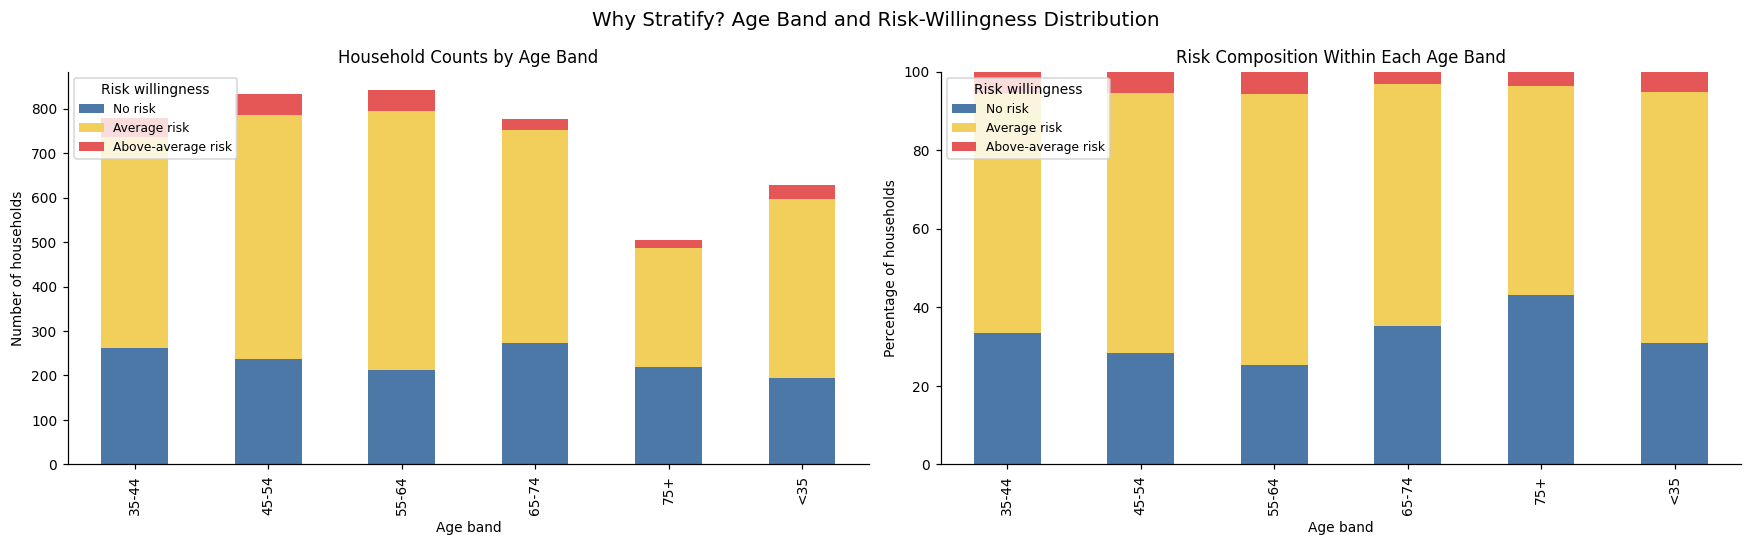

In [104]:
# Count households in each age-band and risk-willingness combination.
pre_split_table = pd.crosstab(  hh["age_band"],   hh["risk_willingness"]).reindex(columns=[0, 1, 2], fill_value=0)
pre_split_table.columns = ["No risk", "Average risk", "Above-average risk"]


print("HOUSEHOLDS BEFORE THE TRAIN/VALIDATION/TEST SPLIT")
print("=" * 75)
display(pre_split_table)

# Convert counts into percentages within each age band.
# Each row will add up to 100 percent.
pre_split_percent = pre_split_table.div( pre_split_table.sum(axis=1),axis=0) * 100
print("=" * 75)
print("RISK-WILLINGNESS PERCENTAGES WITHIN EACH AGE BAND")
print("=" * 75)
display(pre_split_percent.round(1))

# Create count and percentage charts side by side.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))
colors = ["#4C78A8", "#F2CF5B", "#E45756"]

# Left chart: the number of households in each group.
pre_split_table.plot(kind="bar", stacked=True, ax=axes[0],color=colors)
axes[0].set_title("Household Counts by Age Band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Number of households")
axes[0].legend(title="Risk willingness", loc="upper left", fontsize=8)

# Right chart: the percentage composition of each age band.
pre_split_percent.plot(kind="bar",stacked=True,ax=axes[1],color=colors)
axes[1].set_title("Risk Composition Within Each Age Band")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Percentage of households")
axes[1].set_ylim(0, 100)
axes[1].legend(title="Risk willingness", loc="upper left", fontsize=8)

fig.suptitle("Why Stratify? Age Band and Risk-Willingness Distribution", fontsize=13)
plt.tight_layout()
plt.show()



### Creating leakage-safe data partitions

The household IDs are split into training, validation, and test partitions before exploratory analysis. Stratification preserves the joint distribution of age band and risk willingness, while the household-level split prevents rows from the same household from crossing partitions. Only the training partition is used to fit later transformations and clustering decisions.

In [105]:
#Split  by household before exploration so validation and test information cannot influence model choices.
strata = hh["age_band"] + "|" + hh["risk_willingness"].astype(str) #combines each household age group and risk willingness into strata
counts = strata.value_counts()
strata = strata.where(strata.map(counts) >= 10, "other")      # merge tiny strata
note("split", "n_strata", strata.nunique())

train_val, test = train_test_split(hh, test_size=SPLIT["test"], stratify=strata, random_state=SEED) #split was define previously as 15%. stratify uses the age/risk composition.
train, val = train_test_split(train_val, test_size=SPLIT["val"] / (SPLIT["train"] + SPLIT["val"]),stratify=strata.loc[train_val.index], random_state=SEED) #strata.loc selects the strata belonging to the same rows as in train_val.
parts = {"train": train.reset_index(drop=True), "val": val.reset_index(drop=True),"test": test.reset_index(drop=True)}

for name, d in parts.items():
    note("split", f"{name}_households", len(d))
    note("split", f"{name}_weight_share", d["weight"].sum() / hh["weight"].sum())
pd.concat([pd.DataFrame({"household_id": d["household_id"], "partition": n}) for n, d in parts.items()]) \
  .to_csv(DATA_DIR / "scf_split_ids.csv", index=False) # set the folder to download the data for M4
NUMBERS["split"]

{'n_strata': 18,
 'train_households': 3052,
 'train_weight_share': np.float64(0.7033403995202065),
 'val_households': 654,
 'val_weight_share': np.float64(0.1441687614754587),
 'test_households': 654,
 'test_weight_share': np.float64(0.15249083900433474)}

## Step 6 - Implicate structure check

### Checking SCF implicates

Each household should have five implicate rows. This cell checks that structure within the training households and measures how often the financial variables differ across implicates. The results help document the uncertainty represented by the SCF replicate records without allowing test data into the analysis.


In [106]:
##### Verify five implicates per training household and quantify variation across the replicate records.#####

tr_full = full[full["household_id"].isin(parts["train"]["household_id"])] # From the complete dataset, keep all rows whose household ID belongs to the training set.
g = tr_full.groupby("household_id")
note("implicates", "train_households_without_5_rows", int((g.size() != 5).sum()))
for c in ["income", "networth", "liq", "debt"]:
    note("implicates", f"share_where_{c}_varies", float((g[c].nunique() > 1).mean().round(2))) #% of training households have different values for that variable across their five implicates.
NUMBERS["implicates"]

{'train_households_without_5_rows': 0,
 'share_where_income_varies': 0.61,
 'share_where_networth_varies': 0.91,
 'share_where_liq_varies': 0.44,
 'share_where_debt_varies': 0.43}

Why this check matters.
Weve  used implicate 1 as the main one-row-per-household dataset for clustering. This cell confirms that:

* The training households still have all five implicates available in full.
The financial variables can differ across implicates.
* Those differences should be recognized as survey uncertainty rather than automatically treated as errors.
* The full dataset is used here instead of only hh because hh contains just implicate 1, while full contains all five implicates.

## Step 7 - Build features (caps fitted on training data only)

### Building model features

This cell creates the classifier and clustering inputs from the training, validation, and test partitions. Ratios are protected against zero denominators, heavy-tailed dollar values are transformed with asinh, and ratio caps are estimated from training data only before being applied consistently to every partition.


In [107]:
# Build leakage safe financial features; fit caps and transformation parameters using training data only.

def ratio(num, den):
    return (num / den.where(den > 0)).astype(float)       # finantial ratios undefined (NaN) when den <= 0,  to be calculated below.

#Ratio CAPS estimated from training, to be applied latere to Vaidation and testing.
tr = parts["train"]
CAPS = {"dti": float(ratio(tr["debt"], tr["income"]).quantile(CAP_QUANTILE).round(2)), # ratio debt to income = debt / income
        "liq_to_income": float(ratio(tr["liq"], tr["income"]).quantile(CAP_QUANTILE).round(2))} # calculates liquid assets relative to income
note("features", "caps_from_train", CAPS) # A value of 0.99 means the 99th percentile. CAP_Quantile previously define as 0.99
note("features", "train_ratio_undefined_income_le_0", int((tr["income"] <= 0).sum()))
note("features", "train_dti_above_cap", int((ratio(tr["debt"], tr["income"]) > CAPS["dti"]).sum()))
note("features", "train_lti_above_cap", int((ratio(tr["liq"], tr["income"]) > CAPS["liq_to_income"]).sum()))
note("features", "train_fin_zero", int((tr["fin"] <= 0).sum()))

def build_features(df):
    out = df.copy()
    nonpos = out["income"] <= 0 #not counting for incomee less than 0
    out["income_nonpositive"] = nonpos.astype(int)
    dti = ratio(out["debt"], out["income"])
    dti = dti.where(~nonpos, np.where(out["debt"] > 0, CAPS["dti"], 0.0)) #denominator div 0
    out["dti"] = dti.clip(upper=CAPS["dti"])
    lti = ratio(out["liq"], out["income"])
    lti = lti.where(~nonpos, np.where(out["liq"] > 0, CAPS["liq_to_income"], 0.0))
    out["liq_to_income"] = lti.clip(upper=CAPS["liq_to_income"])
    out["equity_share"] = ratio(out["equity"], out["fin"]).fillna(0.0).clip(0, 1)
    for c in ["income", "networth", "liq", "dti", "liq_to_income"]:
        out[f"asinh_{c}"] = np.arcsinh(out[c].astype(float))
    return out

feats = {name: build_features(d) for name, d in parts.items()}  #Built for all the sets using the features fron training

# Clustering variables define the target; classifier variables are the ones a user can give
CLUSTER_FEATURES = ["age", "risk_willingness", "asinh_networth", "asinh_dti",
                    "asinh_liq_to_income", "equity_share"]
CLASSIFIER_FEATURES = ["age", "risk_willingness", "asinh_income", "asinh_networth", "asinh_liq",
                       "asinh_liq_to_income", "income_nonpositive"]

assert not feats["train"][CLUSTER_FEATURES + CLASSIFIER_FEATURES].isna().any().any() #check for missing values and that confirms features follow logic.
NUMBERS["features"]

{'caps_from_train': {'dti': 7.32, 'liq_to_income': 4.42},
 'train_ratio_undefined_income_le_0': 18,
 'train_dti_above_cap': 31,
 'train_lti_above_cap': 31,
 'train_fin_zero': 34}

After runnning the process we've gave every partition the same feature definitions while preventing validation and test data from influencing the preprocessing rules. At the same time we validateed only a few observations were capted form the calculations.

* See Figure 2: skew before and after asinh

The asinh transformation was retained for features where it materially reduced absolute skewness and helped control extreme financial values. The transformation preserves zeros and negative net worth, which makes it appropriate for these variables.

## Step 8 - Outlier check: 3×IQR fences on raw and inverse hyperbolic sine(asinh) transformed features (training data only)

### Measuring outliers and distribution changes

This cell uses training data to calculate 3XIQR fences on both raw and asinh-transformed features. It summarizes how many observations are flagged and writes the audit tables used to document the effect of the transformations without deleting economically plausible households.

In [108]:
# Compare raw and transformed feature distributions using training-fitted 3xIQR outlier fences.
rows = []
for col in ["income", "asinh_income", "networth", "asinh_networth", "liq", "asinh_liq"]:
    x = feats["train"][col].astype(float)
    q1, q3 = x.quantile([0.25, 0.75]) #IQR = q3 - q1
    n = int(((x < q1 - 3 * (q3 - q1)) | (x > q3 + 3 * (q3 - q1))).sum()) #obsevations counted if below lower fence q1 - 3*IQR or above higher fence
    rows.append({"variable": col, "n_beyond_3iqr": n, "min": x.min(), "max": x.max()}) #All values counted as extreme onservations
outliers = pd.DataFrame(rows)
outliers.to_csv(TAB_DIR / "scf_outliers_train.csv", index=False)
note("outliers", "table", outliers.to_dict(orient="records"))
outliers

,variable,n_beyond_3iqr,min,max
0,income,396,0.000000,2.193114e+08
1,asinh_income,30,0.000000,1.989915e+01
2,networth,443,-207050.000000,3.077095e+09
3,asinh_networth,229,-12.933863,2.254040e+01
4,liq,364,0.000000,1.478910e+08
5,asinh_liq,0,0.000000,1.950513e+01


The values are not removed but is proveen that the asinh transfomation has reduce the extreme values and in consecuence reduce their influence.

In [109]:
# Confirm where the outlier audit tables were written and display the relevant preview.
print(TAB_DIR.resolve())
print(os.listdir(TAB_DIR))

/content/drive/MyDrive/Portfolio_pilot/data/raw/outputs/tables
['scf_outliers_train.csv', 'k_selection.csv', 'archetype_profile_train.csv', 'pca_scf_loadings.csv']


## Step 9 - Choose the number of archetypes - preliminary exploration

### Defining candidate clustering models

This cell defines the clustering algorithms and their shared configuration for each candidate number of archetypes. Keeping model construction in one function ensures that comparisons use consistent initialization, scaling, and random-state behavior.

In [110]:
# Create comparable candidate clustering models for each tested archetype count.

def make_model(method, k, seed): #The function creates one of two possible clustering models:
    if method == "kmeans":
        return KMeans(n_clusters=k, n_init=20, random_state=seed) #K clusters
    return GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=seed) #K components

tr = feats["train"] # up to this point contains ; Training data, Implicate 1, Engineered feeatures, Asinh transformed and ratios.

base = weighted_resample(tr, SEED) #resampled version of the training data using survey weights.
                                    #makes clusters more representative of the population.
scaler_c = StandardScaler().fit(base[CLUSTER_FEATURES]) #feature variables now have mean ~0, std ~1
Xb = scaler_c.transform(base[CLUSTER_FEATURES]) #Applies the scaler to the clustering features
Xt = scaler_c.transform(tr[CLUSTER_FEATURES]) #scaler to compleate training set
w = tr["weight"].to_numpy(float) #weights saved for later use
sub = np.random.default_rng(SEED).choice(len(Xb), size=min(3000, len(Xb)), replace=False) #random subset of trainig observations

results = []
for method in ["kmeans", "gmm"]:
    for k in K_RANGE:
        m = make_model(method, k, SEED).fit(Xb)
        ref = m.predict(Xt)
        aris = []
        for b in range(N_BOOTSTRAP):
            rs = weighted_resample(tr, SEED + 1 + b)
            mb = make_model(method, k, SEED + 1 + b).fit(scaler_c.transform(rs[CLUSTER_FEATURES]))
            aris.append(adjusted_rand_score(ref, mb.predict(Xt)))
        results.append({
            "method": method, "k": k,
            "silhouette": silhouette_score(Xb[sub], m.predict(Xb)[sub]),
            "bic": m.bic(Xb) if method == "gmm" else np.nan,
            "stability_ari_mean": np.mean(aris), "stability_ari_sd": np.std(aris),
            "min_cluster_share": (np.bincount(ref, weights=w, minlength=k) / w.sum()).min(),
        })
        print("done:", method, k)
ktab = pd.DataFrame(results)
ktab.to_csv(TAB_DIR / "k_selection.csv", index=False)
note("target", "k_selection", ktab.round(4).to_dict(orient="records"))
ktab.round(3)

done: kmeans 2
done: kmeans 3
done: kmeans 4
done: kmeans 5
done: kmeans 6
done: gmm 2
done: gmm 3
done: gmm 4
done: gmm 5
done: gmm 6


,method,k,silhouette,bic,stability_ari_mean,stability_ari_sd,min_cluster_share
0,kmeans,2,0.220,NaN,0.654,0.157,0.399
1,kmeans,3,0.246,NaN,0.733,0.245,0.086
2,kmeans,4,0.267,NaN,0.787,0.171,0.086
3,kmeans,5,0.259,NaN,0.942,0.017,0.086
4,kmeans,6,0.264,NaN,0.646,0.083,0.084
5,gmm,2,0.175,42482.818,0.804,0.108,0.447
6,gmm,3,0.140,39341.572,0.218,0.123,0.204
7,gmm,4,0.204,8286.440,0.875,0.087,0.039
8,gmm,5,0.220,6779.090,0.800,0.193,0.024
9,gmm,6,0.167,-6567.865,0.588,0.120,0.029


In [111]:
print(N_BOOTSTRAP)

20


## Step 10 - Fit the chosen clustering and label every household -Preliminary analysis, NOT IN M3

* Preliminary five-cluster result to later be use in M4, not part of M3*
* see Figure 1: Target Balance
* & Figure 3,5 features across archetypes for interpretation and quality checking.

In [112]:
SIL_TOLERANCE = 0.01   # silhouette differences smaller than this count as a tie

if CHOSEN_K:
    k = int(CHOSEN_K)
else:
    cand = ktab[(ktab["method"] == CLUSTER_METHOD) & (ktab["min_cluster_share"] >= MIN_CLUSTER_SHARE)]
    if cand.empty:
        cand = ktab[ktab["method"] == CLUSTER_METHOD]
    best_sil = cand["silhouette"].max()
    near_best = cand[cand["silhouette"] >= best_sil - SIL_TOLERANCE]      # options tied with the best
    k = int(near_best.sort_values("stability_ari_mean", ascending=False).iloc[0]["k"])
    print("Tied on silhouette:", near_best["k"].tolist(), "-> most stable:", k)
note("target", "chosen", {"method": CLUSTER_METHOD, "k": k})
print("Chosen:", CLUSTER_METHOD, "k =", k)

final_model = make_model(CLUSTER_METHOD, k, SEED).fit(Xb)

# Order clusters: A0 = most conservative ... A(k-1) = most growth-oriented
lab_b = final_model.predict(Xb)
cols = [CLUSTER_FEATURES.index("risk_willingness"), CLUSTER_FEATURES.index("asinh_networth")]
score = [Xb[lab_b == c][:, cols].sum(axis=1).mean() for c in range(k)]
order = {int(old): new for new, old in enumerate(np.argsort(score))}

for name, d in feats.items():   # fitted on train only; val/test are just labelled
    d["archetype"] = [order[c] for c in final_model.predict(scaler_c.transform(d[CLUSTER_FEATURES]))]

tr = feats["train"]
note("target", "train_weighted_share", (tr.groupby("archetype")["weight"].sum() / tr["weight"].sum()).to_dict())
note("target", "train_count", tr["archetype"].value_counts().sort_index().to_dict())

# Table 3: weighted medians by archetype
prof = tr.groupby("archetype").apply(lambda d: pd.Series({
    **{f"median_{c}": weighted_median(d[c], d["weight"])
       for c in ["age", "income", "networth", "liq", "dti", "liq_to_income", "equity_share"]},
    "mean_risk_willingness": np.average(d["risk_willingness"], weights=d["weight"]),
    "weighted_share": d["weight"].sum() / tr["weight"].sum(),
    "n_households": len(d)}), include_groups=False)
prof.to_csv(TAB_DIR / "archetype_profile_train.csv")
prof.round(2)

Tied on silhouette: [4, 5, 6] -> most stable: 5
Chosen: kmeans k = 5


,median_age,median_income,median_networth,median_liq,median_dti,median_liq_to_income,median_equity_share,mean_risk_willingness,weighted_share,n_households
archetype,,,,,,,,,,
0,39.0,49297.30,-14149.0,1000.0,0.69,0.02,0.00,0.49,0.09,235.0
1,60.0,44162.16,100700.0,1900.0,0.13,0.04,0.00,0.00,0.29,732.0
2,70.0,109891.89,1272300.0,170000.0,0.00,1.41,0.27,0.82,0.09,341.0
3,50.0,145837.84,677750.0,17000.0,1.17,0.11,0.74,0.93,0.25,954.0
4,45.0,93459.46,184650.0,10000.0,0.41,0.10,0.03,1.06,0.28,790.0


## Step 10.1 - Save the model-ready files for M4

In [113]:
keep = ["household_id", "weight", "archetype"] + sorted(set(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
for name, d in feats.items():
    d[keep].to_csv(DATA_DIR / f"scf_{name}.csv", index=False)
print("Saved to", DATA_DIR)

Saved to outputs/processed


## Step 11 Run PCA on the SCF clustering variables

### Reducing SCF dimensions with PCA

This cell standardizes a survey-weighted training resample and fits PCA to the clustering variables. The explained-variance output and score plot provide a lower-dimensional view of the feature structure without changing the primary clustering model.

In [114]:
# Fit PCA on a standardized, training-only weighted resample to inspect lower-dimensional structure.

Xp = weighted_resample(tr, SEED)[CLUSTER_FEATURES].to_numpy(float)
pca_scf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(Xp))
evr_scf = pca_scf.explained_variance_ratio_
note("pca_scf", "explained", evr_scf.tolist())
note("pca_scf", "cumulative", np.cumsum(evr_scf).tolist())
note("pca_scf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_scf), PCA_THRESHOLD) + 1))
note("pca_scf", "n_eigen_gt_1", int((pca_scf.explained_variance_ > 1).sum()))
load_scf = pd.DataFrame(pca_scf.components_.T, index=CLUSTER_FEATURES,
                        columns=[f"PC{i+1}" for i in range(len(CLUSTER_FEATURES))])
load_scf.to_csv(TAB_DIR / "pca_scf_loadings.csv")
print("Cumulative variance:", np.cumsum(evr_scf).round(3))
load_scf.round(3)

Cumulative variance: [0.274 0.513 0.669 0.802 0.908 1.   ]


,PC1,PC2,PC3,PC4,PC5,PC6
age,0.302,0.570,0.346,-0.144,-0.345,0.569
risk_willingness,0.381,-0.492,-0.408,0.213,0.062,0.630
asinh_networth,0.579,0.097,0.202,-0.229,0.737,-0.139
asinh_dti,-0.026,-0.421,0.798,0.426,0.002,0.060
asinh_liq_to_income,0.493,0.262,-0.168,0.662,-0.246,-0.402
equity_share,0.430,-0.421,0.089,-0.512,-0.523,-0.307


The Spearman correlation matrix ** Figure 4 ** and PCA indicate that the archetype variables contain related but non-identical information. Financial variables are expected to show some positive association, while age and risk willingness may contribute a separate behavioral dimension.

* PCA distributes the explained variance across multiple components rather than one dominant factor, suggesting that the five variables capture several dimensions of household financial and risk profiles. These diagnostics support retaining the variables for exploratory K-means clustering, while the PCA is used for interpretation and not as a replacement for the clustering model.

Correlation and PCA help explain the structure of the data, but they do not prove that five clusters are correct. The five-cluster choice remains provisional and should be reported as a modeling decision rather than a conclusion established by PCA.


##  12 - SCF figures

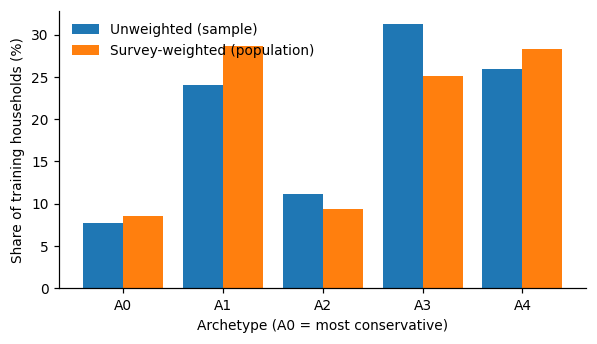

In [115]:
# Figure 1: Target Balance
tr = feats["train"]
arche = sorted(tr["archetype"].unique())

# Figure 1: target balance
g = tr.groupby("archetype")
x = np.arange(len(arche))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(x - 0.2, g.size() / len(tr) * 100, 0.4, label="Unweighted (sample)")
ax.bar(x + 0.2, g["weight"].sum() / tr["weight"].sum() * 100, 0.4, label="Survey-weighted (population)")
ax.set_xticks(x, [f"A{a}" for a in arche])
ax.set_xlabel("Archetype (A0 = most conservative)")
ax.set_ylabel("Share of training households (%)")
ax.legend(frameon=False)
save_fig(fig, "fig01_target_balance")

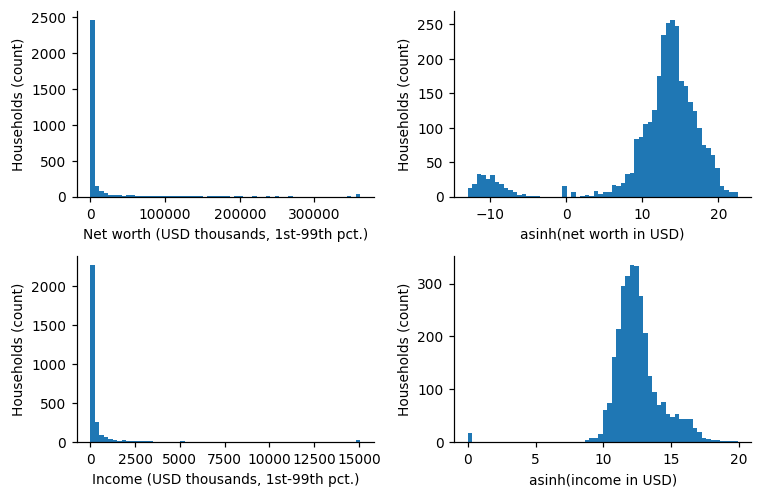

In [116]:
# Figure 2: skew before and after asinh
#Plot the raw-versus-transformed distributions to show how asinh reduces skew without dropping valid values.
fig, axes = plt.subplots(2, 2, figsize=(7, 4.6))
for row, (c, lab) in enumerate([("networth", "Net worth"), ("income", "Income")]):
    lo, hi = tr[c].quantile([0.01, 0.99])
    axes[row, 0].hist(tr[c].clip(lo, hi) / 1e3, bins=60)
    axes[row, 0].set_xlabel(f"{lab} (USD thousands, 1st-99th pct.)")
    axes[row, 1].hist(np.arcsinh(tr[c]), bins=60)
    axes[row, 1].set_xlabel(f"asinh({lab.lower()} in USD)")
    for a in axes[row]:
        a.set_ylabel("Households (count)")
save_fig(fig, "fig02_skew_asinh")

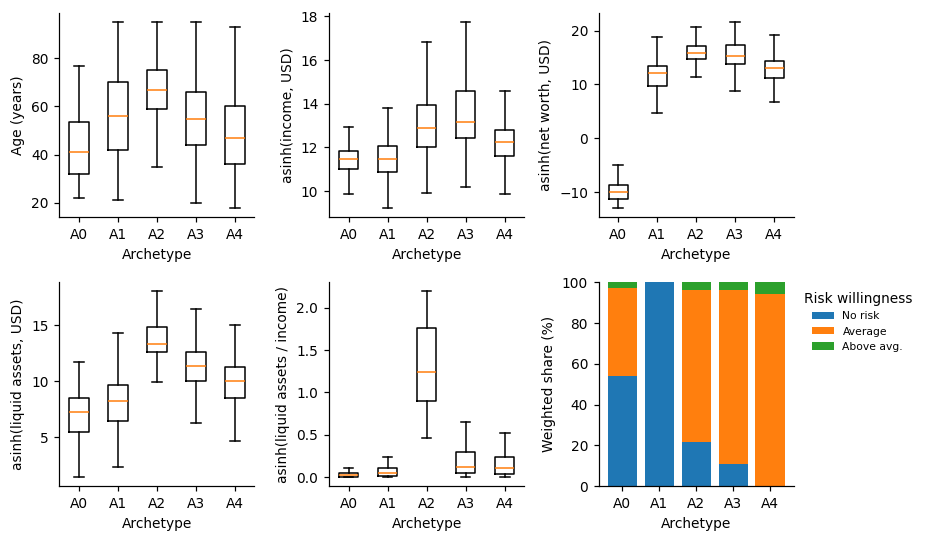

In [117]:
# Figure 3: intake features by archetype
#  Visualize the intake features across archetypes for interpretation and quality checking.
panels = [("age", "Age (years)"), ("asinh_income", "asinh(income, USD)"),
          ("asinh_networth", "asinh(net worth, USD)"), ("asinh_liq", "asinh(liquid assets, USD)"),
          ("asinh_liq_to_income", "asinh(liquid assets / income)")]
fig, axes = plt.subplots(2, 3, figsize=(8.5, 5))
for ax, (c, lab) in zip(axes.flat, panels):
    ax.boxplot([tr.loc[tr["archetype"] == a, c] for a in arche], showfliers=False)
    ax.set_xticks(range(1, len(arche) + 1), [f"A{a}" for a in arche])
    ax.set_xlabel("Archetype")
    ax.set_ylabel(lab)
ax = axes.flat[-1]
ct = pd.crosstab(tr["archetype"], tr["risk_willingness"], values=tr["weight"],
                 aggfunc="sum", normalize="index") * 100
bottom = np.zeros(len(ct))
for r, name in zip(ct.columns, ["No risk", "Average", "Above avg."]):
    ax.bar([f"A{a}" for a in ct.index], ct[r], bottom=bottom, label=name)
    bottom += ct[r].to_numpy()
ax.set_xlabel("Archetype")
ax.set_ylabel("Weighted share (%)")
ax.legend(title="Risk willingness", frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
save_fig(fig, "fig03_features_by_archetype")

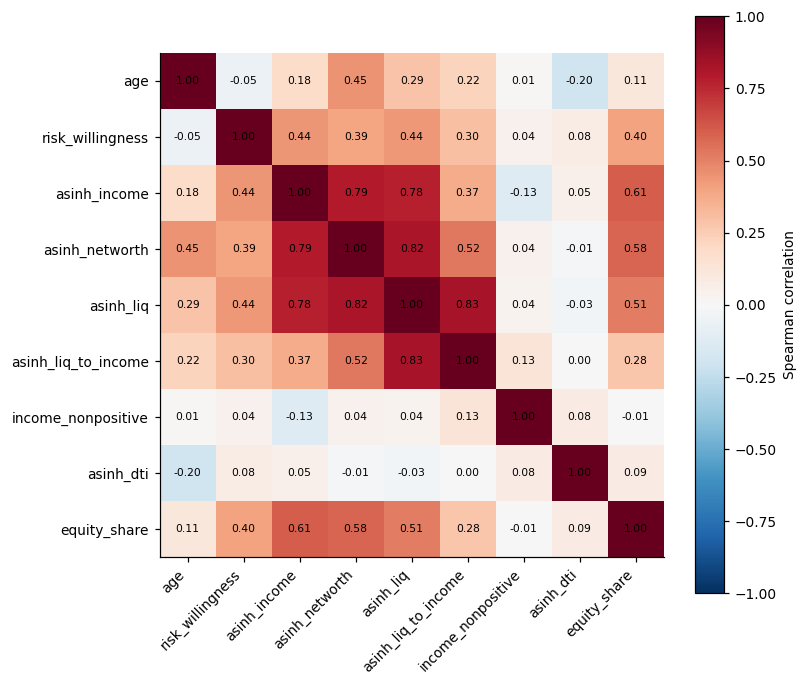

In [118]:
# Figure 4: correlations among features
def corr_plot(df, cols, name, method):
    c = df[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(0.6 * len(cols) + 2, 0.55 * len(cols) + 1.5))
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, label=f"{method.capitalize()} correlation")
    save_fig(fig, name)
    return c

all_feats = list(dict.fromkeys(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
scf_corr = corr_plot(tr, all_feats, "fig04_scf_corr", "spearman") ##spearman is used because the variables are not normally distributed
note("eda", "spearman", scf_corr.round(3).to_dict())

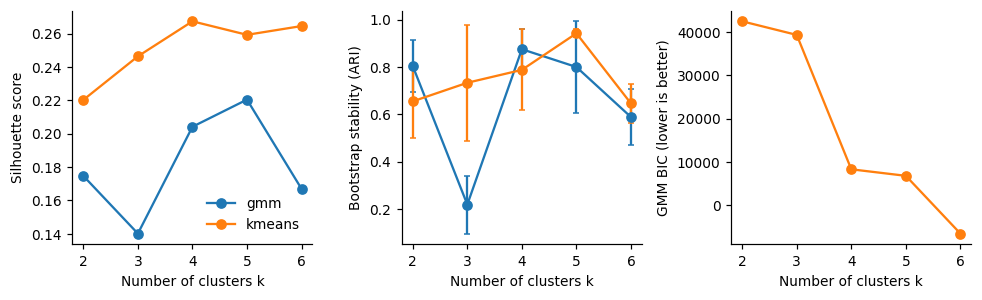

In [119]:
# Figure 5: choosing k
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
for m, d in ktab.groupby("method"):
    axes[0].plot(d["k"], d["silhouette"], marker="o", label=m)
    axes[1].errorbar(d["k"], d["stability_ari_mean"], yerr=d["stability_ari_sd"], marker="o", capsize=2, label=m)
gm = ktab[ktab["method"] == "gmm"]
axes[2].plot(gm["k"], gm["bic"], marker="o", color="C1")
for a, lab in zip(axes, ["Silhouette score", "Bootstrap stability (ARI)", "GMM BIC (lower is better)"]):
    a.set_xlabel("Number of clusters k")
    a.set_ylabel(lab)
axes[0].legend(frameon=False)
save_fig(fig, "fig05_k_selection")

## Step 14 - Load the ETF data and check its structure

In [121]:
from datetime import date

ETF_WIDE_FILE = Path("PortfolioPilot_ETF_Prices.csv")   # one column per ETF, next to the notebook

if not ETF_WIDE_FILE.exists():
    import yfinance as yf
    data = yf.download(tickers=TICKERS, start=ETF_START, end=ETF_END, interval="1d",
                       auto_adjust=True, progress=False)
    data["Close"].to_csv(ETF_WIDE_FILE)                # adjusted closing prices
    Path("etf_download_date.txt").write_text(str(date.today()))
    print("Downloaded on", date.today())
else:
    print("Using saved file:", ETF_WIDE_FILE)

wide = pd.read_csv(ETF_WIDE_FILE, index_col=0, parse_dates=True)
wide.index.name = "date"

# Structure checks
note("etf_raw", "rows_trading_days", len(wide))
note("etf_raw", "columns", wide.shape[1])
note("etf_raw", "date_range", [str(wide.index.min().date()) if wide.index.min() is not None else None, str(wide.index.max().date()) if wide.index.max() is not None else None])
note("etf_raw", "tickers_missing", sorted(set(TICKERS) - set(wide.columns)))
note("etf_raw", "unexpected_columns", sorted(set(wide.columns) - set(TICKERS)))
note("etf_raw", "missing_by_ticker", wide.isna().sum().to_dict())

# Safely extract first valid date to prevent AttributeError if first_valid_index() returns None
first_dates = {}
for c in wide.columns:
    idx = wide[c].first_valid_index()
    first_dates[c] = str(idx.date()) if idx is not None and hasattr(idx, 'date') else None
note("etf_raw", "first_valid_date", first_dates)

if Path("etf_download_date.txt").exists():
    note("etf_raw", "download_date", Path("etf_download_date.txt").read_text())
assert len(wide) > 0, "No prices: the download failed. Delete the CSV and try again later."

# Long format (date, ticker, adj_close) used by Step 15
long = wide.reset_index().melt(id_vars="date", var_name="ticker", value_name="adj_close")
long.to_csv(ETF_FILE, index=False)

print(NUMBERS["etf_raw"])
wide.head()

Using saved file: PortfolioPilot_ETF_Prices.csv
{'rows_trading_days': 2514, 'columns': 9, 'date_range': ['2016-01-04', '2025-12-31'], 'tickers_missing': [], 'unexpected_columns': [], 'missing_by_ticker': {'AGG': 0, 'DBC': 0, 'GLD': 0, 'SPY': 0, 'TIP': 0, 'TLT': 2514, 'VEA': 0, 'VNQ': 0, 'VWO': 0}, 'first_valid_date': {'AGG': '2016-01-04', 'DBC': '2016-01-04', 'GLD': '2016-01-04', 'SPY': '2016-01-04', 'TIP': '2016-01-04', 'TLT': None, 'VEA': '2016-01-04', 'VNQ': '2016-01-04', 'VWO': '2016-01-04'}}


,AGG,DBC,GLD,SPY,TIP,TLT,VEA,VNQ,VWO
date,,,,,,,,,
2016-01-04,79.657745,11.210504,102.889999,169.051758,80.085335,NaN,26.352304,51.486610,23.626699
2016-01-05,79.694611,11.100595,103.180000,169.337738,80.034424,NaN,26.323154,52.480141,23.678740
2016-01-06,79.997124,10.923054,104.669998,167.201614,80.288963,NaN,25.842300,52.336342,23.254969
2016-01-07,79.989723,10.872327,106.150002,163.190170,80.223518,NaN,25.354168,51.316677,22.504095
2016-01-08,80.166832,10.821600,105.680000,161.398941,80.288963,NaN,25.040876,50.630356,22.303366


## Step 15 - Clean ETF prices, compute returns, split by time

In [ ]:
# ---- Load the long-format ETF prices saved in Step 14 (one row per date and ticker) ----
eraw = pd.read_csv(ETF_FILE, parse_dates=["date"])

# ---- Data-quality checks (counts go into Table 1 of the report) ----
note("etf", "rows", len(eraw))                                                   # total rows loaded
note("etf", "tickers_missing", sorted(set(TICKERS) - set(eraw["ticker"])))       # expected ETFs not in the file
note("etf", "duplicate_date_ticker", int(eraw.duplicated(["date", "ticker"]).sum()))  # same ETF twice on one day
note("etf", "missing_prices", int(eraw["adj_close"].isna().sum()))               # blank prices
note("etf", "non_positive_prices", int((eraw["adj_close"] <= 0).sum()))          # impossible prices (0 or negative)

# ---- Fix problems found above ----
eraw = eraw.drop_duplicates(["date", "ticker"], keep="last")   # keep one row per ETF per day
eraw = eraw[eraw["adj_close"] > 0]                             # drop impossible prices

# Reshape to wide format: one row per trading day, one column per ETF, in the order of TICKERS
prices = eraw.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS]

# Count trading days where an ETF has no price
gaps = prices.isna().sum()
note("etf", "missing_days_by_ticker", gaps[gaps > 0].to_dict())

# Fill isolated one-day gaps with the previous day's price (= zero return that day);
# longer gaps are left empty and those days are dropped below
filled = prices.ffill(limit=1)
note("etf", "cells_forward_filled", int(prices.isna().sum().sum() - filled.isna().sum().sum()))
prices = filled.dropna()                                       # keep only days with all 9 prices

note("etf", "trading_days", len(prices))
note("etf", "date_range", [str(prices.index.min().date()), str(prices.index.max().date())])

# ---- Daily log returns: log(today's price / yesterday's price) ----
ret = np.log(prices).diff().dropna()                           # first day has no previous price, so it is dropped

# ---- Time-based split (no shuffling: the future must never inform the past) ----
# train: 2016 to 2021 | validation: 2022 to 2023 | test: 2024 to 2025
t_end, v_end = pd.Timestamp(ETF_TRAIN_END), pd.Timestamp(ETF_VAL_END)
etf_parts = {"train": ret.loc[:t_end],
             "val":   ret.loc[t_end + pd.Timedelta(days=1): v_end],
             "test":  ret.loc[v_end + pd.Timedelta(days=1):]}

# Save each period for M4 and record its size and date range (Table 2 of the report)
for name, d in etf_parts.items():
    d.to_csv(DATA_DIR / f"etf_returns_{name}.csv")
    note("etf_split", name, {"days": len(d), "from": str(d.index.min().date()), "to": str(d.index.max().date())})

# Show the cleaning counts and the split summary
NUMBERS["etf"], NUMBERS["etf_split"]

## Step 16 - ETF exploration (training period only)

In [ ]:
etr = etf_parts["train"]

z = (etr - etr.mean()) / etr.std()
flags = z.abs() > 5
note("etf_outliers", "n_flagged_by_ticker", flags.sum().to_dict())
note("etf_outliers", "dates", [str(d.date()) for d in etr.index[flags.any(axis=1)]])
note("etf_eda", "annual_vol_train", (etr.std() * np.sqrt(252)).to_dict())
print("Extreme-return dates:", NUMBERS["etf_outliers"]["dates"])

etf_corr = corr_plot(etr, TICKERS, "fig06_etf_corr", "pearson")
note("etf_eda", "corr_train", etf_corr.round(3).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.8), sharex=True)
vol = etr.rolling(252).std() * np.sqrt(252) * 100
for c in TICKERS:
    axes[0].plot(vol.index, vol[c], lw=1, label=c)
axes[0].set_ylabel("Rolling 252-day vol.\n(% per year)")
axes[0].legend(ncol=5, frameon=False, fontsize=7)
axes[1].plot(etr.index, etr["SPY"].rolling(252).corr(etr["AGG"]), color="k", lw=1)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_ylabel("Rolling 252-day corr.\nSPY vs AGG")
axes[1].set_xlabel("Date")
save_fig(fig, "fig07_etf_rolling")

# Inspect extreme ETF returns (training period)
List every daily return beyond 5 training standard deviations, with its date, ETF and size, to check whether each is a real market event or a data error.

In [ ]:
z = (etr - etr.mean()) / etr.std()
flagged = (etr[z.abs() > 5].stack().rename("log_return").to_frame()
           .assign(z=z.stack(), pct_return=lambda d: (np.exp(d["log_return"]) - 1) * 100)
           .round(2))
flagged.index.names = ["date", "ticker"]
flagged.sort_index()

## PCA on ETF returns and the scree plot

In [ ]:
pca_etf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(etr))
evr_etf = pca_etf.explained_variance_ratio_
note("pca_etf", "explained", evr_etf.tolist())
note("pca_etf", "cumulative", np.cumsum(evr_etf).tolist())
note("pca_etf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_etf), PCA_THRESHOLD) + 1))
load_etf = pd.DataFrame(pca_etf.components_.T, index=TICKERS, columns=[f"PC{i+1}" for i in range(9)])
load_etf.to_csv(TAB_DIR / "pca_etf_loadings.csv")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (title, evr) in zip(axes, [("SCF clustering variables", evr_scf), ("ETF daily returns", evr_etf)]):
    xs = np.arange(1, len(evr) + 1)
    ax.bar(xs, evr * 100, label="Per component")
    ax.plot(xs, np.cumsum(evr) * 100, marker="o", color="C3", label="Cumulative")
    ax.axhline(PCA_THRESHOLD * 100, ls="--", color="grey", lw=1, label=f"{int(PCA_THRESHOLD*100)}% threshold")
    ax.set_xticks(xs)
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Variance explained (%)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=7)
save_fig(fig, "fig08_pca_scree")
print("ETF cumulative variance:", np.cumsum(evr_etf).round(3))
load_etf.iloc[:, :3].round(3)